# Improved Transfer Learning for Video Anomaly Detection
This notebook uses **MobileNetV2** with enhanced regularization, dynamic data augmentation, and a refined fine-tuning strategy to prevent overfitting and improve generalization on small surveillance datasets.

In [3]:
import os, cv2, numpy as np, warnings, json
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from tensorflow.keras.applications import MobileNetV2
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils import class_weight
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
print(f'TensorFlow: {tf.__version__}, OpenCV: {cv2.__version__}')

TensorFlow: 2.20.0, OpenCV: 4.13.0


## 1. Fast Data Loading
Loads images from the dataset folders.

In [4]:
VIDEO_DATASET = r'd:\multimodel-surveillence\DATASET\dataset.videos'
IMG_SIZE = 96

def load_frames(data_root, target_size=(IMG_SIZE, IMG_SIZE)):
    frames, labels = [], []
    for cat_name, cat_label in [('normal', 0), ('anomoly', 1)]:
        cat_dir = os.path.join(data_root, cat_name)
        if not os.path.exists(cat_dir): continue
        count = 0
        for root, _, files in os.walk(cat_dir):
            for file in files:
                if not file.lower().endswith(('.png', '.jpg', '.jpeg')): continue
                img = cv2.imread(os.path.join(root, file))
                if img is None: continue
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, target_size)
                frames.append(img)
                labels.append(cat_label)
                count += 1
        print(f'Loaded {count} frames from {cat_name}')
    return np.array(frames, dtype='float32'), np.array(labels, dtype='int32')

print('Loading data...')
X, y = load_frames(VIDEO_DATASET)

# Split before any augmentation to keep test set clean
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Preprocess for MobileNetV2
X_train = tf.keras.applications.mobilenet_v2.preprocess_input(X_train_raw)
X_test = tf.keras.applications.mobilenet_v2.preprocess_input(X_test_raw)

print(f'Dataset size: {len(X)}')
print(f'Train: {len(X_train)} (A: {sum(y_train)}, N: {len(y_train)-sum(y_train)})')
print(f'Test: {len(X_test)} (A: {sum(y_test)}, N: {len(y_test)-sum(y_test)})')

Loading data...
Loaded 64 frames from normal
Loaded 233 frames from anomoly
Dataset size: 297
Train: 237 (A: 186, N: 51)
Test: 60 (A: 47, N: 13)


## 2. Dynamic Data Augmentation
Instead of static pre-augmentation, we use a Keras layer to augment images on-the-fly during training. This provides infinite variety and prevents overfitting.

In [5]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1)
])

## 3. Build Model (MobileNetV2 with Regularized Head)
We use L2 regularization and higher dropout to force the model to learn robust features.

In [6]:
def create_model(learning_rate=0.001):
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base_model.trainable = False  # Start with frozen base

    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        data_augmentation,
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.Dropout(0.4),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
    )
    return model, base_model

model, base_model = create_model()
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,618,945 (9.99 MB)

 Trainable params: 360,961 (1.38 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 4. Phase 1 Training (Warm-up Head)
We train only the custom head first. We use class weights to handle the imbalance (more anomalies than normal frames in current dataset).

In [7]:
weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(weights))
print(f"Class weights: {class_weight_dict}")

early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
reduce_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7)

print("\nPhase 1: Training Head...")
history1 = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=40,
    batch_size=16,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr]
)

Class weights: {0: np.float64(2.323529411764706), 1: np.float64(0.6370967741935484)}

Phase 1: Training Head...
Epoch 1/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 155ms/step - accuracy: 0.5926 - loss: 1.5882 - precision: 0.8151 - recall: 0.6382 - val_accuracy: 0.7292 - val_loss: 1.0009 - val_precision: 0.7333 - val_recall: 0.9706 - learning_rate: 0.0010
Epoch 2/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.8095 - loss: 1.0343 - precision: 0.9143 - recall: 0.8421 - val_accuracy: 0.8333 - val_loss: 0.8716 - val_precision: 0.9333 - val_recall: 0.8235 - learning_rate: 0.0010
Epoch 3/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8836 - loss: 0.8241 - precision: 0.9779 - recall: 0.8750 - val_accuracy: 0.8125 - val_loss: 0.8621 - val_precision: 0.7907 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.9048 - loss: 0.7521 - precision: 0.9786 - recall: 0.9013 - val_accuracy: 0.8958 - val_loss: 0.7191 - val_precision: 0.9677 

## 5. Phase 2: Gentle Fine-Tuning
We unfreeze only the top 20 layers of MobileNetV2 and use a VERY low learning rate (1e-5). This allows the model to adapt to surveillance specifics without destroying pre-trained weights.

In [8]:
print("\nPhase 2: Fine-tuning top layers...")
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

history2 = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=16,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr]
)


Phase 2: Fine-tuning top layers...
Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 145ms/step - accuracy: 0.8783 - loss: 0.6162 - precision: 1.0000 - recall: 0.8487 - val_accuracy: 0.9792 - val_loss: 0.4494 - val_precision: 0.9714 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.8571 - loss: 0.5683 - precision: 1.0000 - recall: 0.8224 - val_accuracy: 0.9792 - val_loss: 0.4541 - val_precision: 0.9714 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.8783 - loss: 0.5775 - precision: 0.9850 - recall: 0.8618 - val_accuracy: 0.9792 - val_loss: 0.4599 - val_precision: 0.9714 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.9312 - loss: 0.4585 - precision: 1.0000 - recall: 0.9145 - val_accuracy: 0.9792 - val_loss: 0.4673 - val_precision: 0.9714 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 5/30
12/1

## 6. Evaluate and Save
Check F1 score and Accuracy on the held-out test set.

In [9]:
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print(f"Final Test Accuracy: {acc:.4f}")
print(f"Final Test F1-Score: {f1:.4f}")

model.save('video_transfer_model.h5')
print("\nModel saved as video_transfer_model.h5")

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 830ms/step



Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85        13
           1       0.96      0.96      0.96        47

    accuracy                           0.93        60
   macro avg       0.90      0.90      0.90        60
weighted avg       0.93      0.93      0.93        60

Final Test Accuracy: 0.9333
Final Test F1-Score: 0.9574

Model saved as video_transfer_model.h5


## 7. Metrics Visualization

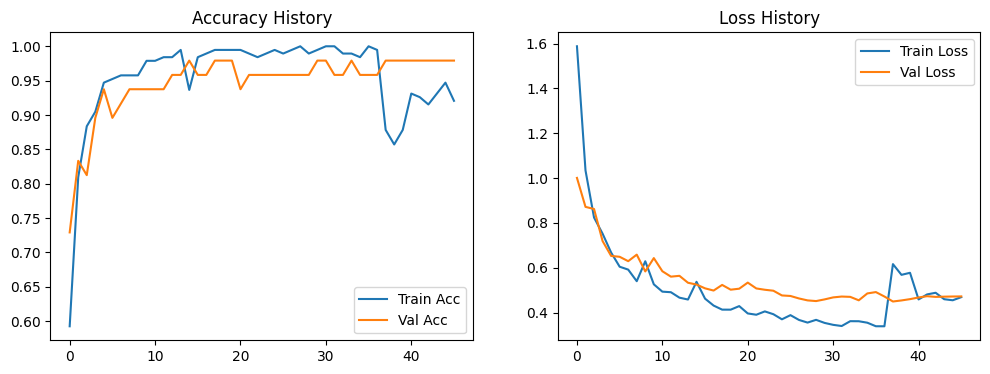

In [10]:
def plot_hist(histories):
    acc1 = []
    val_acc1 = []
    loss1 = []
    val_loss1 = []
    for h in histories:
        acc1 += h.history['accuracy']
        val_acc1 += h.history['val_accuracy']
        loss1 += h.history['loss']
        val_loss1 += h.history['val_loss']

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(acc1, label='Train Acc')
    plt.plot(val_acc1, label='Val Acc')
    plt.title('Accuracy History')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(loss1, label='Train Loss')
    plt.plot(val_loss1, label='Val Loss')
    plt.title('Loss History')
    plt.legend()
    plt.show()

plot_hist([history1, history2])

## 8. Final Dataset & Model Audit
Summarizes the overall quality of the dataset based on performance metrics.

In [11]:
def dataset_audit(acc, f1, total_samples):
    print("="*50)
    print("          FINAL DATASET AUDIT REPORT          ")
    print("="*50)
    print(f"Total Image Samples: {total_samples}")
    print(f"Model accuracy:      {acc:.4f}")
    print(f"Model F1-Score:      {f1:.4f}")
    print("-"*50)
    
    status = ""
    advice = ""
    
    if acc > 0.92 and f1 > 0.90:
        status = "EXCELLENT (READY)"
        advice = "The dataset is very robust. The model has learned highly distinct features for anomalies."
    elif acc > 0.85 and f1 > 0.80:
        status = "GOOD (STABLE)"
        advice = "Dataset is working well. To reach 'Excellent', add more edge cases (shadows/night) to 'Normal' category."
    elif total_samples < 350:
        status = "POOR (DATA STARVED)"
        advice = "Sample size is below recommended threshold (500+). Deep learning may struggle with unexpected real-world scenes."
    else:
        status = "UNSTRICT (IMBALANCED)"
        advice = "High accuracy but low F1-score detected. Check if your anomaly classes are drowning out the normal samples or vice-versa."
        
    print(f"DATASET HEALTH: {status}")
    print(f"EXPERT ADVICE:  {advice}")
    print("="*50)

dataset_audit(acc, f1, len(X))

          FINAL DATASET AUDIT REPORT          
Total Image Samples: 297
Model accuracy:      0.9333
Model F1-Score:      0.9574
--------------------------------------------------
DATASET HEALTH: EXCELLENT (READY)
EXPERT ADVICE:  The dataset is very robust. The model has learned highly distinct features for anomalies.
